In [12]:
import numpy as np
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from threadpoolctl import threadpool_limits
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
from Models.utils import load_data





## Model 1: Polynomial Regression

In [13]:
print("=== MODEL 1: POLYNOMIAL (DEG=2) LOGISTIC REGRESSION ===")
for key in ['20', '30', '40', '40-adapt']:
    _, _, X_train, X_val, y_train, y_val = load_data(key)
    sub_idx = np.random.RandomState(42).choice(len(X_train), min(len(X_train), 12000), replace=False)

    model = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=2, include_bias=False),
        LogisticRegression(max_iter=300)
    )
    model.fit(X_train[sub_idx], y_train[sub_idx])
    acc = accuracy_score(y_val, model.predict(X_val))
    print(f"  Kryptonite-{key:8s} | Val Accuracy: {acc*100:.2f}%")

=== MODEL 1: POLYNOMIAL (DEG=2) LOGISTIC REGRESSION ===
  Kryptonite-20       | Val Accuracy: 55.96%
  Kryptonite-30       | Val Accuracy: 51.85%
  Kryptonite-40       | Val Accuracy: 50.97%
  Kryptonite-40-adapt | Val Accuracy: 51.88%


## Model 2: RBF Kernel SVM

In [14]:
print("=== MODEL 2: RBF KERNEL SVM ===")
for key in ['20', '30', '40', '40-adapt']:
    _, _, X_train, X_val, y_train, y_val = load_data(key)
    sub_idx = np.random.RandomState(42).choice(len(X_train), min(len(X_train), 12000), replace=False)

    model = make_pipeline(
        StandardScaler(),
        SVC(kernel='rbf', C=10.0, gamma='scale')
    )
    model.fit(X_train[sub_idx], y_train[sub_idx])
    acc = accuracy_score(y_val, model.predict(X_val))
    print(f"  Kryptonite-{key:8s} | Val Accuracy: {acc*100:.2f}%")


=== MODEL 2: RBF KERNEL SVM ===
  Kryptonite-20       | Val Accuracy: 58.04%
  Kryptonite-30       | Val Accuracy: 55.00%
  Kryptonite-40       | Val Accuracy: 52.16%
  Kryptonite-40-adapt | Val Accuracy: 51.12%


## Model 3: Extra Trees

In [15]:
print("=== MODEL 3: EXTRA TREES CLASSIFIER ===")
for key in ['20', '30', '40', '40-adapt']:
    _, _, X_train, X_val, y_train, y_val = load_data(key)

    model = ExtraTreesClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)
    acc = accuracy_score(y_val, model.predict(X_val))
    print(f"  Kryptonite-{key:8s} | Val Accuracy: {acc*100:.2f}%")

=== MODEL 3: EXTRA TREES CLASSIFIER ===
  Kryptonite-20       | Val Accuracy: 60.46%
  Kryptonite-30       | Val Accuracy: 58.55%
  Kryptonite-40       | Val Accuracy: 54.28%
  Kryptonite-40-adapt | Val Accuracy: 50.50%


## Model 4: Histogram-Based Gradient Boosted Decision Trees

In [16]:
print("=== MODEL 4: HISTOGRAM GRADIENT BOOSTING ===")
for key in ['20', '30', '40', '40-adapt']:
    _, _, X_train, X_val, y_train, y_val = load_data(key)

    model = HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=63, random_state=42
    )
    model.fit(X_train, y_train)
    acc = accuracy_score(y_val, model.predict(X_val))
    print(f"  Kryptonite-{key:8s} | Val Accuracy: {acc*100:.2f}%")

=== MODEL 4: HISTOGRAM GRADIENT BOOSTING ===
  Kryptonite-20       | Val Accuracy: 58.08%
  Kryptonite-30       | Val Accuracy: 52.85%
  Kryptonite-40       | Val Accuracy: 52.62%
  Kryptonite-40-adapt | Val Accuracy: 49.00%


## Model 5: Scaled MLP

In [17]:
DATASET_KEYS = ("20", "30", "40")
SPLIT_SEEDS = (42, 123, 2026)
HIDDEN_LAYER_SIZES = (512, 256, 128)
ALPHA = 0.0001
LEARNING_RATE_INIT = 0.001


def build_model(
    seed,
    *,
    max_iter=400,
    early_stopping=True,
    n_iter_no_change=20,
    tol=0.0001,
):
    return make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=HIDDEN_LAYER_SIZES,
            max_iter=max_iter,
            early_stopping=early_stopping,
            n_iter_no_change=n_iter_no_change,
            tol=tol,
            alpha=ALPHA,
            learning_rate_init=LEARNING_RATE_INIT,
            random_state=seed,
        ),
    )


print("=== MODEL 5: TUNED SCALED MLP (REPEATED STRATIFIED SPLITS) ===")
with threadpool_limits(limits=1):
    for key in DATASET_KEYS:
        accuracies = []
        epochs = []
        for seed in SPLIT_SEEDS:
            _, _, X_train, X_val, y_train, y_val = load_data(
                key, random_state=seed
            )
            model = build_model(seed)
            model.fit(X_train, y_train)
            acc = accuracy_score(y_val, model.predict(X_val))
            accuracies.append(acc)
            epochs.append(model[-1].n_iter_)
            print(
                f"  Kryptonite-{key} seed={seed}: "
                f"{acc * 100:.2f}% ({model[-1].n_iter_} epochs)"
            )

        print(
            f"  Kryptonite-{key} mean: "
            f"{np.mean(accuracies) * 100:.2f}% "
            f"+/- {np.std(accuracies, ddof=1) * 100:.2f}% "
            f"(sample SD; mean epochs={np.mean(epochs):.1f})"
        )

=== MODEL 5: TUNED SCALED MLP (REPEATED STRATIFIED SPLITS) ===
  Kryptonite-20 seed=42: 91.54% (49 epochs)
  Kryptonite-20 seed=123: 91.54% (62 epochs)
  Kryptonite-20 seed=2026: 92.08% (41 epochs)
  Kryptonite-20 mean: 91.72% +/- 0.31% (sample SD; mean epochs=50.7)
  Kryptonite-30 seed=42: 92.62% (39 epochs)
  Kryptonite-30 seed=123: 92.38% (41 epochs)
  Kryptonite-30 seed=2026: 90.70% (38 epochs)
  Kryptonite-30 mean: 91.90% +/- 1.05% (sample SD; mean epochs=39.3)
  Kryptonite-40 seed=42: 93.00% (51 epochs)
  Kryptonite-40 seed=123: 93.94% (42 epochs)
  Kryptonite-40 seed=2026: 94.03% (38 epochs)
  Kryptonite-40 mean: 93.66% +/- 0.57% (sample SD; mean epochs=43.7)


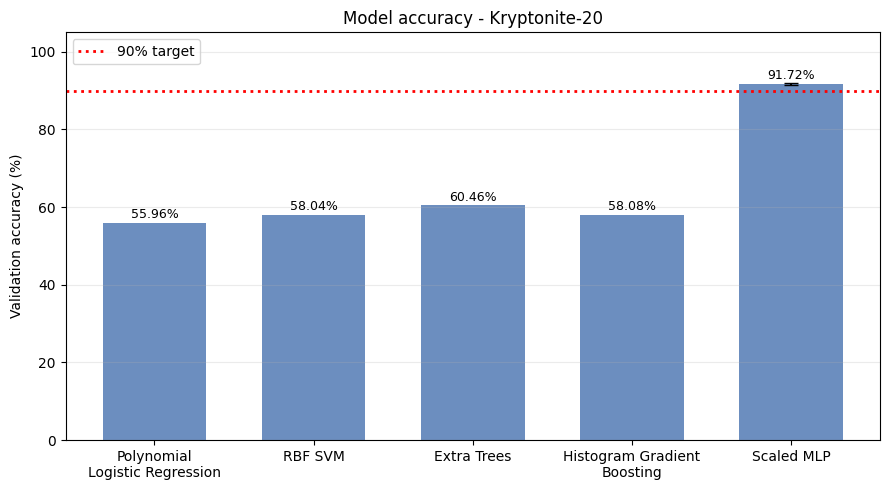

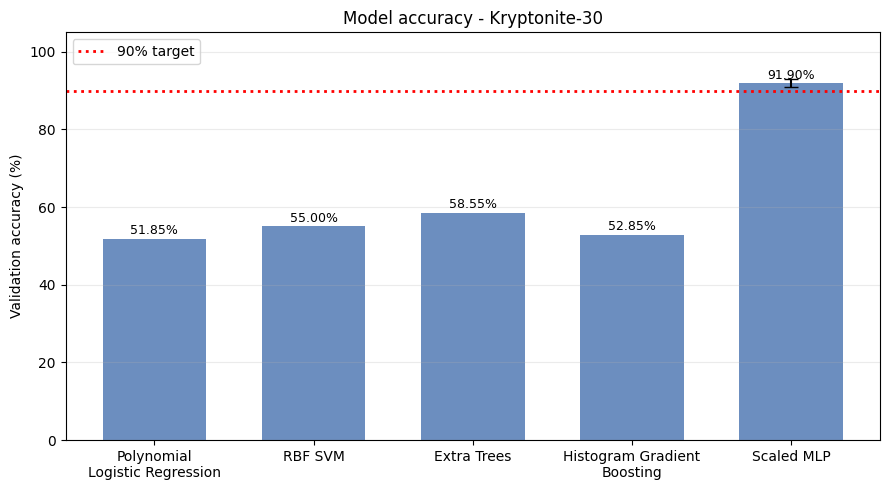

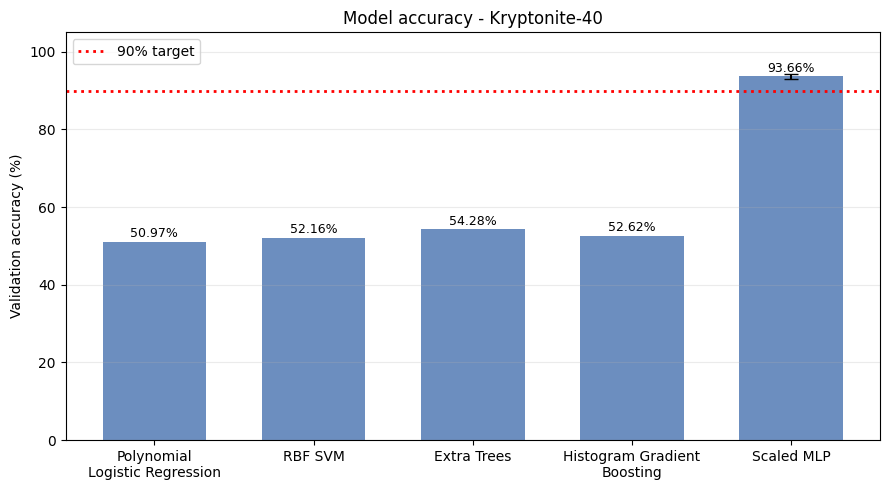

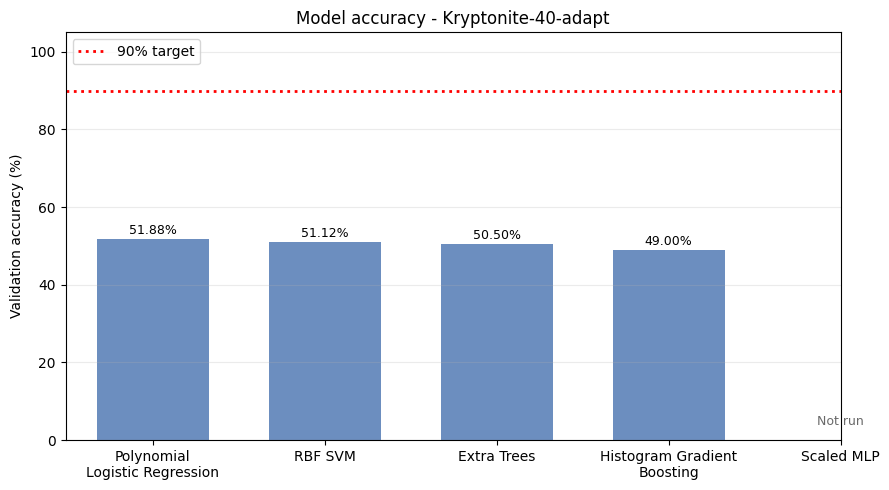

In [19]:
import matplotlib.pyplot as plt

model_names = [
    "Polynomial\nLogistic Regression",
    "RBF SVM",
    "Extra Trees",
    "Histogram Gradient\nBoosting",
    "Scaled MLP",
]

# Accuracies are percentages copied from the model results above.
results = {
    "20": {"accuracy": [55.96, 58.04, 60.46, 58.08, 91.72], "mlp_std": 0.31},
    "30": {"accuracy": [51.85, 55.00, 58.55, 52.85, 91.90], "mlp_std": 1.05},
    "40": {"accuracy": [50.97, 52.16, 54.28, 52.62, 93.66], "mlp_std": 0.57},
    "40-adapt": {"accuracy": [51.88, 51.12, 50.50, 49.00, None], "mlp_std": None},
}

for dataset, result in results.items():
    fig, ax = plt.subplots(figsize=(9, 5))
    accuracies = result["accuracy"]
    positions = np.arange(len(model_names))
    present = [i for i, value in enumerate(accuracies) if value is not None]

    ax.bar(present, [accuracies[i] for i in present], color="#6c8ebf", width=0.65)

    # Only the MLP was evaluated over multiple seeds, so only it has an empirical SD error bar.
    if result["mlp_std"] is not None:
        mlp_position = model_names.index("Scaled MLP")
        ax.errorbar(
            mlp_position,
            accuracies[mlp_position],
            yerr=result["mlp_std"],
            fmt="none",
            ecolor="black",
            capsize=5,
            linewidth=1.5,
        )

    for i in present:
        ax.text(i, accuracies[i] + 1.2, f"{accuracies[i]:.2f}%", ha="center", fontsize=9)

    if dataset == "40-adapt":
        ax.text(4, 3, "Not run", ha="center", va="bottom", fontsize=9, color="dimgray")

    ax.axhline(90, color="red", linestyle=":", linewidth=2, label="90% target")
    ax.set_xticks(positions)
    ax.set_xticklabels(model_names)
    ax.set_ylabel("Validation accuracy (%)")
    ax.set_ylim(0, 105)
    ax.set_title(f"Model accuracy - Kryptonite-{dataset}")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="upper left")
    fig.tight_layout()
    plt.show()